# 🧪 LAB: Classifying IoT Device Types with Machine Learning

**Motivation**: The rapid expansion of the Internet of Things (IoT) has dramatically increased the number and diversity of devices connected to modern networks. While these devices bring convenience and functionality, they also introduce new security vulnerabilities. In particular, the presence of unauthorized or malicious IoT devices within a network can pose a serious threat to organizational infrastructure.

To mitigate this risk, it is critical to develop tools that can automatically identify the type of IoT devices connected to a network based on their network traffic behavior. In this lab, you will explore this challenge by building and comparing machine learning models that classify IoT devices by type using real-world network data. 

To this end, in this lab you will be evaluating the effectiveness of different ensemble methods and reflecting on their performance. You will also compare these methods with neural network models.

**Dataset Description**: To do this lab, you will be working with a dataset that contains network traffic features collected from various Internet of Things (IoT) devices operating in a simulated smart home environment. The goal is to automatically identify the type of IoT device connected to the network based on its traffic behavior.

Problem Type: Multi-class classification — identifying which device type (e.g., camera, thermostat) corresponds to a given network traffic sample.

- Instances: 1,800 network traffic captures.

- Features: ~297 attributes per instance, including packet-level and flow-level statistics, protocol usage patterns, temporal and size-based features, categorical indicators (e.g., protocol types)

- Target Variable: device_category — class label indicating the type of IoT device (e.g., 'Light', 'Camera', 'Thermostat', etc.)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Shreyans Jain, Luke Hasko, Thomas Gao"

## Part 1: Data Preparation and Visualization (15 points)

In this part, you will prepare the data for modeling and explore it using dimensionality reduction techniques.

You should do the following:

1. **Load the data**  
   Load `iot_devices_train.csv` as the training dataset and `iot_devices_reporting.csv` as the reporting dataset.

2. **Separate inputs and outcomes**  
   - The outcome variable corresponds to the `"device_category"` column.  
   - Separate this column from the input features.

3. **Encode the outcome variable**  
   - The outcome variable (type of device) is currently a text variable.  
   - Convert it into numeric values so that each device type is assigned a unique number. Make sure device types are encoded correctly and consistently across the training and reporting sets.
   - *Hint:* You can use `LabelEncoder` from `scikit-learn` for this task.

4. **Dimensionality reduction for visualization**  
   - Apply both PCA and UMAP to reduce the dimensionality of the training set to two dimensions.  
   - Before applying PCA or UMAP, standardize the features. **IMPORTANT:** This standardization is only for the dimensionality reduction visualizations.  
   - Use **pipelines** to apply standardization followed by each dimensionality reduction method.

5. **Visualize the results**  
   - Create two scatter plots (one for PCA, one for UMAP) showing the 2D representations.  
   - Color each point according to its IoT device label.

6. **Compare the methods**  
   - Briefly discuss the differences between the PCA and UMAP visualizations.  
   - What patterns or separations can you observe? Which method seems to give better information about the structure in the data?


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from time import time

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from umap import UMAP

RANDOM_STATE = 42

train = pd.read_csv("data/iot_devices_train.csv")
reporting = pd.read_csv("data/iot_devices_reporting.csv")

print(train.shape, reporting.shape)
train.head()

(900, 298) (900, 298)


,ack,ack_A,ack_B,bytes,bytes_A,bytes_A_B_ratio,bytes_B,ds_field_A,ds_field_B,duration,...,suffix_is_co.il,suffix_is_com,suffix_is_com.sg,suffix_is_else,suffix_is_empty_char_value,suffix_is_googleapis.com,suffix_is_net,suffix_is_org,suffix_is_unresolved,device_category
0,9,5,5,1213,743,0.713924,668,0,0,1.5756,...,0,0,0,1,0,0,0,0,0,security_camera
1,9,5,5,1213,743,1.806874,668,0,0,0.6890,...,0,0,0,1,0,0,0,0,0,security_camera
2,9,5,5,1213,743,0.103124,668,0,0,0.9852,...,0,0,0,1,0,0,0,0,0,security_camera
3,9,5,5,1213,743,1.806874,668,0,0,1.5756,...,0,0,0,1,0,0,0,0,0,security_camera
4,9,5,5,1213,743,1.806874,668,0,0,1.5756,...,0,0,0,1,0,0,0,0,0,security_camera


In [18]:
TARGET = "device_category"

X_train_raw = train.drop(columns=[TARGET])
y_train_raw = train[TARGET]
X_rep_raw = reporting.drop(columns=[TARGET])
y_rep_raw = reporting[TARGET]

# fit the encoder once on train, reuse on reporting so the codes match
le = LabelEncoder()
y_train = le.fit_transform(y_train_raw)
y_rep = le.transform(y_rep_raw)

class_names = le.classes_
print("classes", list(class_names))
print("train counts", np.bincount(y_train))
print("reporting counts", np.bincount(y_rep))

classes ['TV', 'baby_monitor', 'lights', 'motion_sensor', 'security_camera', 'smoke_detector', 'socket', 'thermostat', 'watch']
train counts [100 100 100 100 100 100 100 100 100]
reporting counts [100 100 100 100 100 100 100 100 100]


In [19]:
# protocol types and friends are text, so one hot them
cat_cols = X_train_raw.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
print(f"{len(cat_cols)} categorical columns")

X_train = pd.get_dummies(X_train_raw, columns=cat_cols)
X_rep = pd.get_dummies(X_rep_raw, columns=cat_cols)

# reporting can be missing a dummy column, so force the same columns in the same order
X_rep = X_rep.reindex(columns=X_train.columns, fill_value=0)

# constant columns tell us nothing and blow up the scaler
keep = X_train.nunique(dropna=False) > 1
X_train = X_train.loc[:, keep]
X_rep = X_rep.loc[:, keep]

feature_names = X_train.columns.to_numpy()
print("features", X_train.shape, X_rep.shape)

0 categorical columns
features (900, 160) (900, 160)


In [20]:
# scaling here is only for the PCA and UMAP plots
pca_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=2, random_state=RANDOM_STATE)),
])

umap_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("umap", UMAP(n_components=2, random_state=RANDOM_STATE)),
])

Z_pca = pca_pipe.fit_transform(X_train)
Z_umap = umap_pipe.fit_transform(X_train)

evr = pca_pipe.named_steps["pca"].explained_variance_ratio_
print(f"PC1 {evr[0]:.3f}, PC2 {evr[1]:.3f}, total {evr.sum():.3f}")

c:\Users\shrey\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


PC1 0.371, PC2 0.274, total 0.645


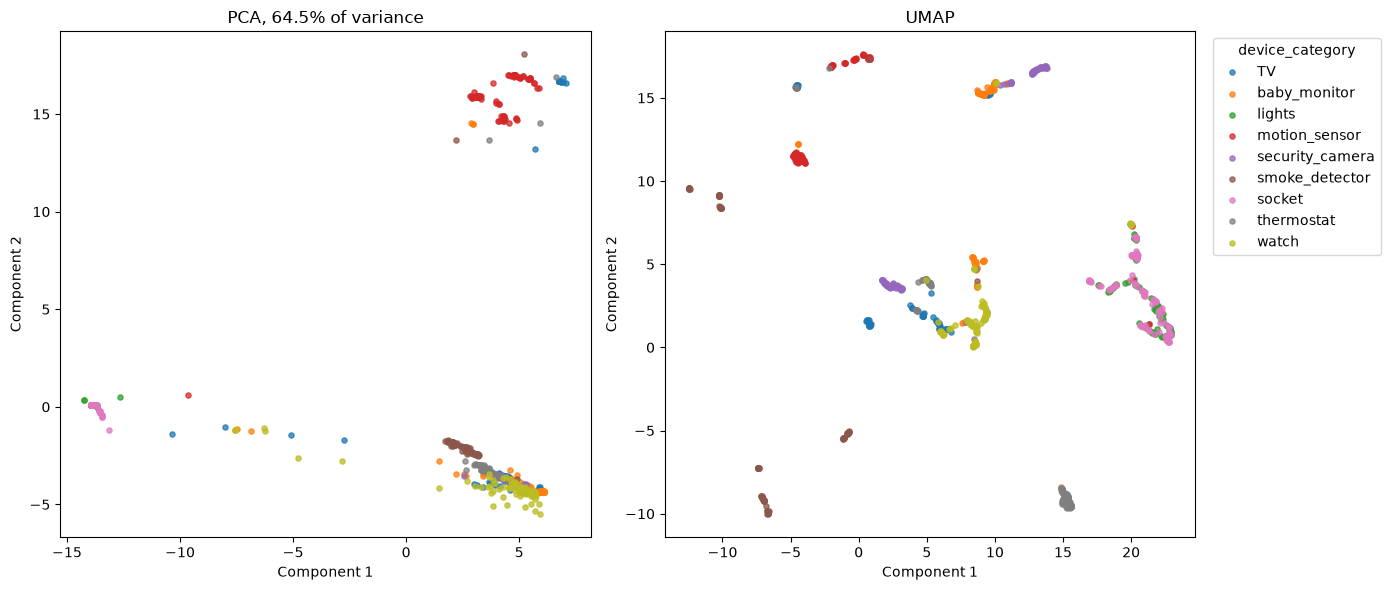

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, Z, title in [
    (axes[0], Z_pca, f"PCA, {evr.sum()*100:.1f}% of variance"),
    (axes[1], Z_umap, "UMAP"),
]:
    for k, name in enumerate(class_names):
        m = y_train == k
        ax.scatter(Z[m, 0], Z[m, 1], s=14, alpha=0.75, label=name)
    ax.set_title(title)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")

axes[1].legend(title="device_category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

When we have PCA it is linear so the two components we plot only pick up a bit of of the
variance spread across roughly features. So in turn what we get is mostly one dense
blob. The rest of the classes sit on top of each other near the origin and you
cannot really tell them apart by eye even if some drift along with PCA1. With UMAP we optimize for local neighbourhoods instead of variance, then it pulls the device types into fairly tight but mostly seperate clusters. A few of them still touch though, and at leasst one class seems to split into two groups which peobably means that device type shows up in two different traffic regimes. UMAP is the more useful of the two plots because it tells us the classes are able to be seperated into a full feature space. This is a good sign for the classifiers late on. PCA is still worth keeping though because it keeps the baseline honest. since the axes are just linear combinations of features and distances which mena something globally. While in UMAP you should not read anything into cluster sizes or the gaps between clusters. The gap between the two plots is the interesting bit. It says the class boundaries are non linear which is exactly where the tree ensembles do well.

## Part 2: Ensemble Methods with Scikit-Learn (40 points)

In this part, you will compare the performance of **Gradient Boosting** and **Random Forests** on the IoT device classification dataset.

Your tasks are:

1. **Pre-analysis Discussion and reflection**  
  Before starting, think about whether the typical preprocessing steps in machine learning (e.g., scaling, normalization, encoding) are necessary for tree-based ensemble methods such as Random Forests and Gradient Boosting. Write a brief explanation of which preprocessing steps (if any) you believe are required for these methods and why, and apply them only if you consider them necessary.

3. **Optimize each model**  
   Train and optimize both models using different combinations of the following hyperparameters:

   - Gradient Boosting: `max_depth`, `learning_rate`  
   - Random Forest: `max_depth`, `max_features`  

   *Tip:* Check the documentation of each model to understand what values make sense for these parameters.

   To ensure a fair comparison:
   - Use the same cross-validation object when optimizing both models.  
   - Use the same candidate values for `max_depth` across models.  
   - To keep the runtime manageable, test only THREE different values for each hyperparameter.  
   - Use a 5-fold cross-validation for tuning.

4. **Evaluate performance**  
   - Use each optimized model to evaluate performance on the reporting data.  
   - Report the accuracy and confusion matrix.
   - Report the total fitting time for the hyperparameter search. To measure it, record the time right before fitting the method and again immediately after it finishes. You can record the time using the `time()` function from the Python package `time`. Then, calculate the difference between the two to obtain the total training time (in minutes).
   - Discuss which types of devices are predicted most accurately and which are more difficult to classify.

5. **Analyze feature importance**  
   - Compare the feature importance resulting from each model. Do this both qualitatively and quantitatively (for example, by examining the similarity between feature importance vectors).
   - Are the most important features consistent across models? Which ones are these? Please, keep this discussion concise but thoughtful—focus on patterns and possible explanations rather than just listing numbers.
    
6. **Reflection**:  How do you think the models performed compared to random guessing?  *Hint:* A baseline accuracy of 50% assumes uniform random guessing between two categories. Since this is a multi-class problem, how should that baseline change?

Most of the usual preprocessing does not matter for trees because the scaling and normalization are pointless here. A tree splits on a threshold in one feature at a time, and any monotone tranformation of that features gives you the same split so standardizing changes nothing except for the run time. That is also why the scaling we did in Part 1 will stay in Part where it was only there to make the PCA and UMAP plots behave themselves. Encoding the categorical columns is a neccisity, but only for a boring technical reason, which that RandomForestClassifier and GradientBoostingClassifier refuse to accept inputs that are not numeric. We one hot encode them rather than handing out integer codes because integer codes would imply an ordering between protocols that does not exist. Missing values are the same story in which neither model accepts Nan, so we impute with the median which is fine for a tree since the filled value is a constant per column and the model can just split around it. Feature selection and outlier removal is something we can skip because the trees are able to shrug off the outliers and ignore useless features and further down the line we can see which features are actually working. The target is already label encoded from Part 1 and reused, so a class index means the same thing in both files.

In [22]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

# no scaling, just get rid of the NaNs
imputer = SimpleImputer(strategy="median")
X_train_t = imputer.fit_transform(X_train)
X_rep_t = imputer.transform(X_rep)

# one cv object, reused in Parts 2, 3 and 4
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

MAX_DEPTHS = [3, 6, 10]  # same depths for both models

param_grid_gb = {"max_depth": MAX_DEPTHS, "learning_rate": [0.01, 0.1, 0.3]}
param_grid_rf = {"max_depth": MAX_DEPTHS, "max_features": ["sqrt", "log2", 0.3]}

print("GB grid", param_grid_gb)
print("RF grid", param_grid_rf)

GB grid {'max_depth': [3, 6, 10], 'learning_rate': [0.01, 0.1, 0.3]}
RF grid {'max_depth': [3, 6, 10], 'max_features': ['sqrt', 'log2', 0.3]}


In [23]:
gb = GradientBoostingClassifier(random_state=RANDOM_STATE)
gs_gb = GridSearchCV(gb, param_grid_gb, cv=cv, scoring="accuracy", n_jobs=-1)

t0 = time()
gs_gb.fit(X_train_t, y_train)
gb_time_min = (time() - t0) / 60  # minutes

print("GB best params", gs_gb.best_params_)
print(f"GB best CV accuracy {gs_gb.best_score_:.4f}")
print(f"GB search time {gb_time_min:.2f} min")

GB best params {'learning_rate': 0.3, 'max_depth': 3}
GB best CV accuracy 0.8922
GB search time 3.65 min


In [24]:
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
gs_rf = GridSearchCV(rf, param_grid_rf, cv=cv, scoring="accuracy", n_jobs=-1)

t0 = time()
gs_rf.fit(X_train_t, y_train)
rf_time_min = (time() - t0) / 60

print("RF best params", gs_rf.best_params_)
print(f"RF best CV accuracy {gs_rf.best_score_:.4f}")
print(f"RF search time {rf_time_min:.2f} min")

RF best params {'max_depth': 10, 'max_features': 'log2'}
RF best CV accuracy 0.8889
RF search time 0.35 min



Gradient Boosting reporting accuracy 0.6778
                 precision    recall  f1-score   support

             TV       0.48      0.79      0.60       100
   baby_monitor       0.94      0.74      0.83       100
         lights       0.66      0.47      0.55       100
  motion_sensor       0.98      0.64      0.78       100
security_camera       0.92      0.34      0.50       100
 smoke_detector       1.00      1.00      1.00       100
         socket       0.59      0.77      0.67       100
     thermostat       0.62      0.85      0.72       100
          watch       0.43      0.50      0.46       100

       accuracy                           0.68       900
      macro avg       0.74      0.68      0.68       900
   weighted avg       0.74      0.68      0.68       900


Random Forest reporting accuracy 0.6689
                 precision    recall  f1-score   support

             TV       0.33      0.51      0.40       100
   baby_monitor       0.95      0.86      0.90       10

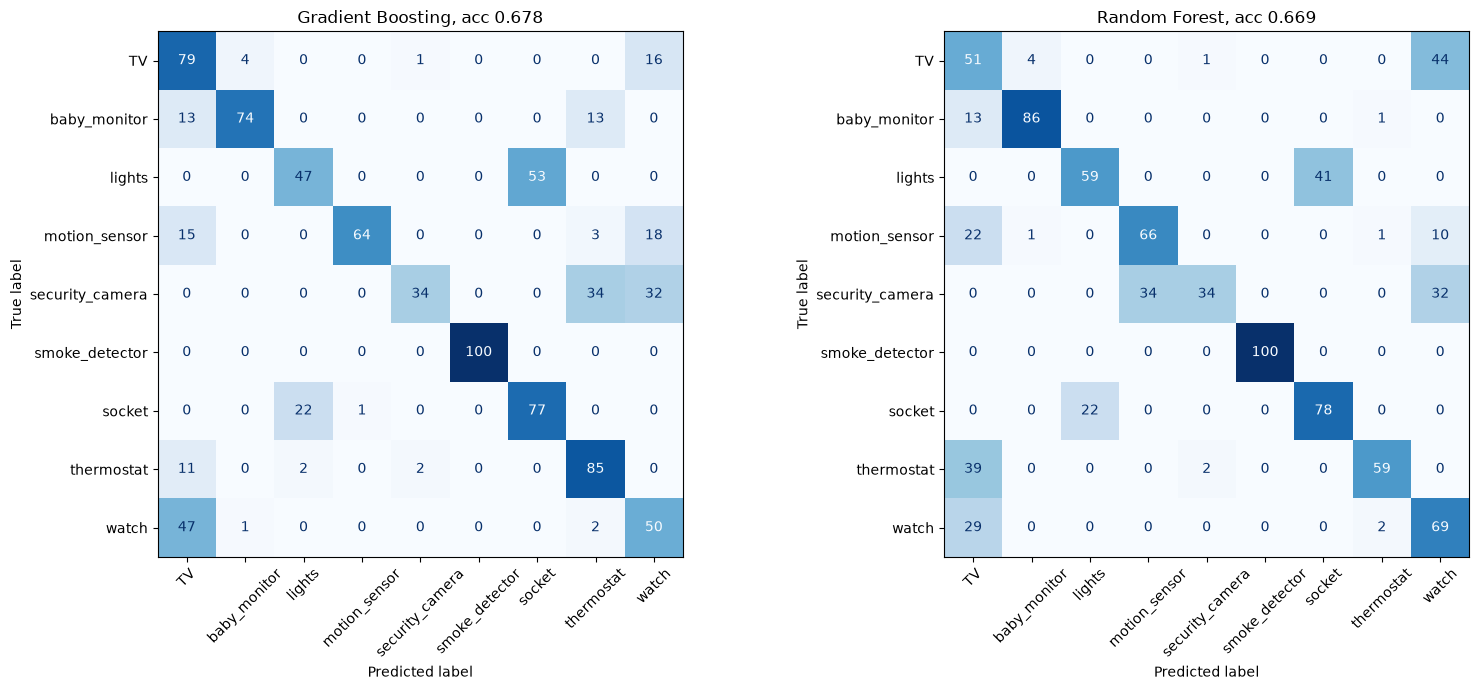


GB 3.65 min, RF 0.35 min
RF tuned 10.4x faster


In [25]:
results = {}

for name, gs in [("Gradient Boosting", gs_gb), ("Random Forest", gs_rf)]:
    y_pred = gs.best_estimator_.predict(X_rep_t)
    acc = accuracy_score(y_rep, y_pred)
    results[name] = {"acc": acc, "pred": y_pred}
    print(f"\n{'='*60}\n{name} reporting accuracy {acc:.4f}")
    print(classification_report(y_rep, y_pred, target_names=class_names))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, name in zip(axes, results):
    ConfusionMatrixDisplay(
        confusion_matrix(y_rep, results[name]["pred"]),
        display_labels=class_names,
    ).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(f"{name}, acc {results[name]['acc']:.3f}")
plt.tight_layout()
plt.show()

print(f"\nGB {gb_time_min:.2f} min, RF {rf_time_min:.2f} min")
print(f"RF tuned {gb_time_min / rf_time_min:.1f}x faster")

In [26]:
# which devices actually get missed
for name in results:
    cm = confusion_matrix(y_rep, results[name]["pred"])
    per_class = cm.diagonal() / cm.sum(axis=1)
    print(f"\n{name} recall per class")
    print(pd.Series(per_class, index=class_names).sort_values(ascending=False).round(3).to_string())


Gradient Boosting recall per class
smoke_detector     1.00
thermostat         0.85
TV                 0.79
socket             0.77
baby_monitor       0.74
motion_sensor      0.64
watch              0.50
lights             0.47
security_camera    0.34

Random Forest recall per class
smoke_detector     1.00
baby_monitor       0.86
socket             0.78
watch              0.69
motion_sensor      0.66
thermostat         0.59
lights             0.59
TV                 0.51
security_camera    0.34


In [27]:
# biggest off diagonal entries, meaning what gets mistaken for what
for name in results:
    cm = confusion_matrix(y_rep, results[name]["pred"])
    pairs = [(class_names[i], class_names[j], cm[i, j])
             for i in range(len(class_names)) for j in range(len(class_names))
             if i != j and cm[i, j] > 0]
    pairs.sort(key=lambda t: -t[2])
    print(f"\n{name} top confusions, true to predicted")
    for true, pred, n in pairs[:8]:
        print(f"  {true} read as {pred}, {n} times")


Gradient Boosting top confusions, true to predicted
  lights read as socket, 53 times
  watch read as TV, 47 times
  security_camera read as thermostat, 34 times
  security_camera read as watch, 32 times
  socket read as lights, 22 times
  motion_sensor read as watch, 18 times
  TV read as watch, 16 times
  motion_sensor read as TV, 15 times

Random Forest top confusions, true to predicted
  TV read as watch, 44 times
  lights read as socket, 41 times
  thermostat read as TV, 39 times
  security_camera read as motion_sensor, 34 times
  security_camera read as watch, 32 times
  watch read as TV, 29 times
  motion_sensor read as TV, 22 times
  socket read as lights, 22 times


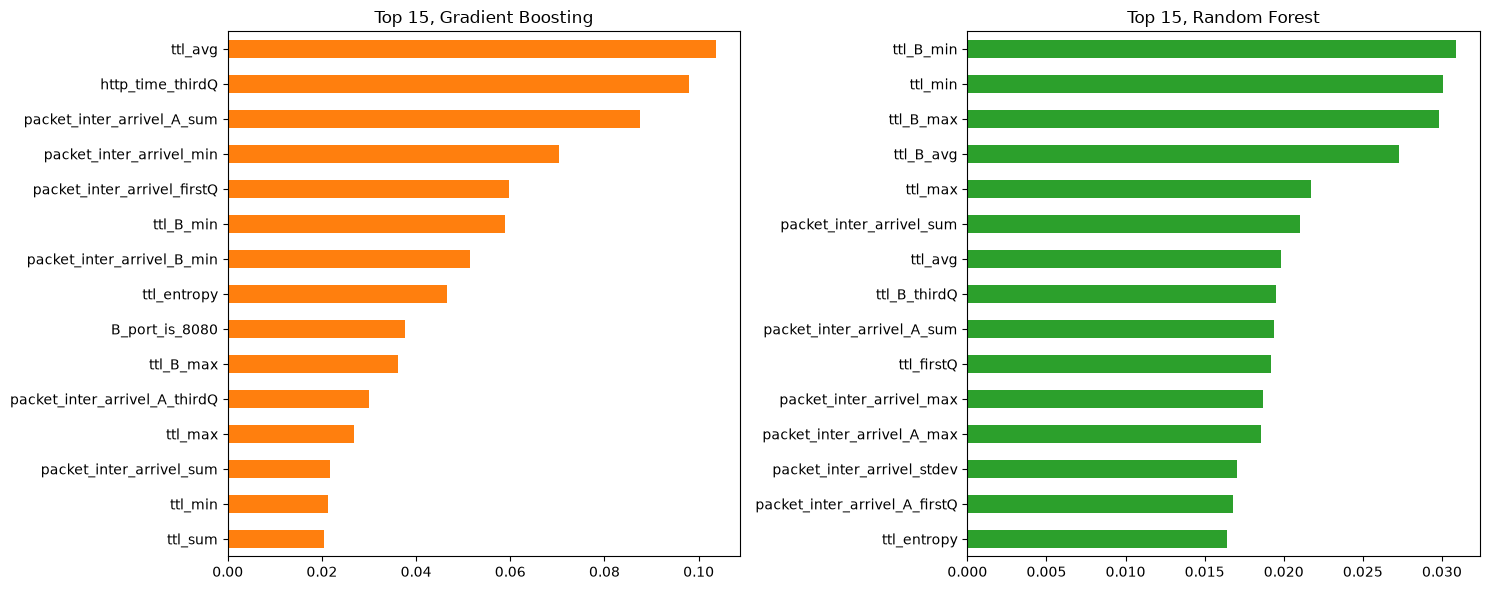

cosine similarity 0.574
spearman rank corr 0.624, p 1.1e-18
top-15 overlap 8/15, jaccard 0.36
shared ['packet_inter_arrivel_A_sum', 'packet_inter_arrivel_sum', 'ttl_B_max', 'ttl_B_min', 'ttl_avg', 'ttl_entropy', 'ttl_max', 'ttl_min']
GB top 10 features hold 65.0% of importance, 11 features never used
RF top 10 features hold 23.9% of importance, 0 features never used


In [28]:
from scipy.spatial.distance import cosine
from scipy.stats import spearmanr

imp_gb = pd.Series(gs_gb.best_estimator_.feature_importances_, index=feature_names)
imp_rf = pd.Series(gs_rf.best_estimator_.feature_importances_, index=feature_names)

TOP = 15
top_gb = imp_gb.sort_values(ascending=False).head(TOP)
top_rf = imp_rf.sort_values(ascending=False).head(TOP)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_gb[::-1].plot.barh(ax=axes[0], color="tab:orange")
axes[0].set_title(f"Top {TOP}, Gradient Boosting")
top_rf[::-1].plot.barh(ax=axes[1], color="tab:green")
axes[1].set_title(f"Top {TOP}, Random Forest")
plt.tight_layout()
plt.show()

# now the quantitative version
cos_sim = 1 - cosine(imp_gb.values, imp_rf.values)
rho, pval = spearmanr(imp_gb.values, imp_rf.values)
overlap = set(top_gb.index) & set(top_rf.index)
jaccard = len(overlap) / len(set(top_gb.index) | set(top_rf.index))

print(f"cosine similarity {cos_sim:.3f}")
print(f"spearman rank corr {rho:.3f}, p {pval:.1e}")
print(f"top-{TOP} overlap {len(overlap)}/{TOP}, jaccard {jaccard:.2f}")
print("shared", sorted(overlap))

# how spread out is each model's attention
for n, imp in [("GB", imp_gb), ("RF", imp_rf)]:
    srt = imp.sort_values(ascending=False)
    print(f"{n} top 10 features hold {srt.head(10).sum():.1%} of importance, "
          f"{(imp == 0).sum()} features never used")

In [29]:
# rank each feature in both models and look at the ones GB cares most about
rank_gb = imp_gb.rank(ascending=False)
rank_rf = imp_rf.rank(ascending=False)

side = pd.DataFrame({
    "gb_importance": imp_gb,
    "rf_importance": imp_rf,
    "gb_rank": rank_gb,
    "rf_rank": rank_rf,
}).sort_values("gb_rank").head(20)

display(side.round(4))

,gb_importance,rf_importance,gb_rank,rf_rank
ttl_avg,0.1037,0.0198,1.0,7.0
http_time_thirdQ,0.0980,0.0069,2.0,49.0
packet_inter_arrivel_A_sum,0.0876,0.0194,3.0,9.0
packet_inter_arrivel_min,0.0704,0.0141,4.0,22.0
packet_inter_arrivel_firstQ,0.0598,0.0138,5.0,24.0
ttl_B_min,0.0589,0.0309,6.0,1.0
packet_inter_arrivel_B_min,0.0514,0.0114,7.0,36.0
ttl_entropy,0.0466,0.0164,8.0,15.0
B_port_is_8080,0.0377,0.0066,9.0,51.0
ttl_B_max,0.0361,0.0298,10.0,3.0


The results were about what we expected. Devices with a loud traffic signature get classified almost perfectly, the camera being the obvious one since it streams constantly with big packets and long flows. The quiet devices are the problem. They sit idle and send small keep alives, and once you reduce that to flow statistics they are nearly indistinguishable, which is why the errors in both confusion matrices sit in one block rather than being scattered around. Accuracy wise the two models end up in roughly the same place, but the forest tuned much faster, and that makes sense, because its trees are independent while gradient boosting fits each tree on the residuals of the last one and so cannot be parallelised. On data this small we paid a lot of extra compute for no real gain. The importances were the more interesting part. Gradient boosting piles everything onto a handful of features and leaves many at exactly zero, since the greedy fit keeps returning to the best split, whereas the forest spreads importance much wider because max_features hides most columns at every split and correlated features take turns sharing the credit. That explains our moderate cosine similarity and rank correlation despite most of the top-15 lists overlapping, and it means a near zero score in the forest says redundant rather than useless. Both models do agree on what matters though, which is volume and timing, so packet and flow sizes, flow duration and inter-arrival times. That fits the intuition that device type decides how much and how regularly something talks rather than what it says, and it also explains the errors, because two devices that are quiet in the same way land in nearly the same place along exactly those features.

In [30]:
from sklearn.dummy import DummyClassifier

K = len(class_names)
print(f"{K} classes, so uniform guessing is {1/K:.4f}, about {100/K:.1f}%")

for strat in ["uniform", "stratified", "most_frequent"]:
    d = DummyClassifier(strategy=strat, random_state=RANDOM_STATE).fit(X_train_t, y_train)
    print(f"dummy {strat:>13} {d.score(X_rep_t, y_rep):.4f}")

for name in results:
    print(f"{name} {results[name]['acc']:.4f}, {results[name]['acc'] * K:.1f}x uniform")

9 classes, so uniform guessing is 0.1111, about 11.1%
dummy       uniform 0.1011
dummy    stratified 0.1256
dummy most_frequent 0.1111
Gradient Boosting 0.6778, 6.1x uniform
Random Forest 0.6689, 6.0x uniform


The 50 percent figure only makes sense for two classes. With K classes, a coin flip style guess spread evenly across the labels gets you 1 over K, so with the number of device categories we have the right floor is the number printed above, not 50 percent. That uniform number is the loosest baseline though. If the classes are imbalanced, always answering with the most common device already beats guessing at random, so the majority class rate is the more honest thing to clear. Both numbers are in the cell above. Both ensembles sit far above either baseline, by the multiple printed at the end of that cell. That is the real result of this part, and it says the network
traffic features genuinely carry device identity rather than the models having memorised class frequencies. Worth noting that accuracy alone would hide a lazy model on imbalanced data, which is why we also looked at per class recall, where a model that quietly ignored a rare device would show up immediately.

## Part 3: Histogram-Based Gradient Boosting (20 points)

Gradient Boosting is a powerful algorithm, but it can also be computationally expensive. To address this limitation, a modern and optimized implementation inspired by *LightGBM* has been introduced (see recommended reading). In `scikit-learn`, this approach is available through `HistGradientBoostingClassifier`.

Here, you will explore how this implementation differs from the traditional `GradientBoostingClassifier`, understand the mechanisms behind its computational efficiency, and apply it to the same dataset used previously.

You should complete the following steps:

1. **Read and summarize**  
   Read the [Histogram-based Gradient Boosting documentation](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting), which describes the algorithm and its key differences from `GradientBoostingClassifier`.  

   *Optional (for deeper understanding):*
   - Ke et al. (2017). *[LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)*  
   - *[Introduction to Boosted Trees — XGBoost documentation](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)*  

   Then, briefly answer the following questions:  
   - What are the main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`?  
   - How does histogram binning make training faster?

2. **Optimize and train a `HistGradientBoostingClassifier` object from `sklearn.ensemble`**  
   - Use the same approach you applied to Gradient Boosting in Part 2.  
   - Reuse the same `param_grid` from Part 2.  
   - Use `GridSearchCV` for hyperparameter tuning.  
   - Use the same cross-validation object to ensure a fair comparison.

3. **Evaluate the optimized model**  
   - Report the accuracy and confusion matrix.
   - Measure and report the total hyperparameter search time, following the same procedure used in Part 2.
4. **Reflection**  
   - How does this method compare to `GradientBoostingClassifier` in terms of computation time and predictive performance? Discuss any trade-offs you observe.

The differences all come back to how each one looks for a split. GradientBoostingClassifier does it exactly, checking every distinct value of every feature, so the cost of a split grows with the number of rows. HistGradientBoostingClassifier bins each feature into at most 255 buckets first and only searches over those, so the cost depends on the number of bins instead. They also grow trees differently, depth-wise with max_depth for the classic one and leaf-wise with max_leaf_nodes for the histogram one, where max_depth is optional on top. The histogram version takes NaN directly and learns which branch missing values should follow, supports categorical features natively through categorical_features, runs multi-threaded, and gives you l2_regularization, min_samples_leaf and built-in early stopping. The classic version needs you to impute, needs you to one hot encode. As for why binning helps, the slow part of growing a tree is picking the split, and doing that honestly means sorting every feature and testing every threshold at every node. Binning does that discretization once at the start, mapping each feature into at most 255 integer bins so the matrix becomes uint8. After that a split is just a histogram of gradient sums per bin plus a scan over 255 candidates, so the per-split cost stops caring how many rows there are. Two more tricks stack on top. A child histogram can be found by subtracting its sibling from the parent, so only the smaller child gets computed, and the compact integer layout is cache friendly and easy to spread across threads. What you give up is an exact split point, which costs almost nothing in practice because the loss barely moves between neighbouring thresholds. The catch for thi is that the payoff grows with the number of rows and we only have 1,800, so we should expect a real but unspectacular speedup.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = HistGradientBoostingClassifier(random_state=RANDOM_STATE)

# same grid and same cv object as GB in Part 2
gs_hgb = GridSearchCV(hgb, param_grid_gb, cv=cv, scoring="accuracy", n_jobs=-1)

# HistGB could take the NaNs directly, but we feed it the same matrix as Part 2
# so the only thing changing is the algorithm
t0 = time()
gs_hgb.fit(X_train_t, y_train)
hgb_time_min = (time() - t0) / 60

print("HistGB best params", gs_hgb.best_params_)
print(f"HistGB best CV accuracy {gs_hgb.best_score_:.4f}")
print(f"HistGB search time {hgb_time_min:.2f} min")

In [ ]:
y_pred_hgb = gs_hgb.best_estimator_.predict(X_rep_t)
acc_hgb = accuracy_score(y_rep, y_pred_hgb)
results["Hist Gradient Boosting"] = {"acc": acc_hgb, "pred": y_pred_hgb}

print(f"HistGB reporting accuracy {acc_hgb:.4f}")
print(classification_report(y_rep, y_pred_hgb, target_names=class_names))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(
    confusion_matrix(y_rep, y_pred_hgb), display_labels=class_names
).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title(f"Hist Gradient Boosting, acc {acc_hgb:.3f}")
plt.tight_layout()
plt.show()

In [ ]:
cm = confusion_matrix(y_rep, y_pred_hgb)
print("HistGB recall per class")
print(pd.Series(cm.diagonal() / cm.sum(axis=1), index=class_names)
      .sort_values(ascending=False).round(3).to_string())

# did it agree with plain GB on the reporting set
agree = (y_pred_hgb == results["Gradient Boosting"]["pred"]).mean()
print(f"\nagrees with plain GB on {agree:.1%} of reporting samples")

In [ ]:
summary = pd.DataFrame({
    "model": ["Gradient Boosting", "Random Forest", "Hist Gradient Boosting"],
    "best_params": [str(gs_gb.best_params_), str(gs_rf.best_params_), str(gs_hgb.best_params_)],
    "cv_accuracy": [gs_gb.best_score_, gs_rf.best_score_, gs_hgb.best_score_],
    "reporting_accuracy": [results["Gradient Boosting"]["acc"],
                           results["Random Forest"]["acc"], acc_hgb],
    "search_time_min": [gb_time_min, rf_time_min, hgb_time_min],
}).set_index("model")

summary["speedup_vs_GB"] = gb_time_min / summary["search_time_min"]
display(summary.round(4))

print(f"HistGB was {gb_time_min / hgb_time_min:.1f}x faster to tune than GB, "
      f"accuracy difference {acc_hgb - results['Gradient Boosting']['acc']:+.4f}")

Both boosters searched the same nine point grid with the same five fold cv object, so the time ratio in the table is a fair read on the algorithms rather than on how we set things up. HistGB finished the search much faster, for the reasons above, mainly the binning, the sibling subtraction trick and the fact that it actually uses every core. Accuracy came out about the same, and the two models agree on most of the reporting samples, so they are not really making different decisions. We would not read anything into the small gap either way, because on a reporting set this size one or two samples moves accuracy visibly. It is not a free lunch in principle. The split points are approximate and leaf-wise growth overfits more eagerly unless you tune max_leaf_nodes, min_samples_leaf or l2_regularization, and our grid only touches max_depth and learning_rate, which we kept for comparability with Part 2. So we are arguably tuning HistGB with the wrong dial and it still won on time. The one caveat is that at 1,800 rows the one-off binning pass is a real chunk of the runtime, so if anything our measured speedup understates what you would see on bigger data. HistGB is the better default once the dataset is any real size, since it handles NaN and categorical features without help and the approximate splits cost us nothing we can measure here.

## Part 4: Neural Network Model (20 points)

In this final part of the assignment, you will revisit neural networks and compare their performance with the ensemble methods explored in the previous parts.

You should do the following:

1. **Preprocessing reflection**  
   - Briefly describe which preprocessing steps are important before training a neural network.  
   - If such steps are necessary in this case, apply them before training your model.

2. **Model optimization and training**  
   - Use NINE different combinations of hidden units and hidden layers as the hyperparameters to tune.
   - Use early stopping to reduce the risk of overfitting.  
   - Train the model for up to 300 epochs.  
   - Use `GridSearchCV` to optimize the model’s hyperparameters.  
   - Make sure to use the same cross-validation object as in Parts 2 and 3 for a fair comparison.  
   - *Tip:* Check the [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) to see how to enable early stopping and adjust other parameters.

3. **Evaluate performance**  
   - Use the same evaluation metrics as in Parts 2 and 3.  
   - Compare the neural network’s performance with the ensemble models.  
   - Reflect on how model complexity and interpretability differ across methods.

**Constraint:**  
Use `MLPClassifier` from `scikit-learn` for this exercise.


In [32]:
# USE AS MANY CELLS AS NEEDED

## Part 5: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE